# M&A Post-Mortem: Agnico Eagle & Kirkland Lake Gold Merger

This project analyzes the 2021–2022 merger of equals between Agnico Eagle Mines (AEM) and
Kirkland Lake Gold (KL) — an all-stock combination valued at C$13.5B (about US$10.7B at
announcement) that created one of the world's largest gold producers. The goal is to
reconstruct the deal terms and test whether the promised synergies ($0.8B over 5 years,
pre-tax) explain the combined company's results, using margin and return comparisons against
peers (Newmont, Barrick) and the synergies reported in AEM's SEC filings.

In [1]:
import pandas as pd
import yfinance as yf
from sqlalchemy import create_engine, text
import matplotlib.pyplot as plt

engine = create_engine("sqlite:///../data/ma_deal.db")

In [2]:
aem = yf.Ticker("AEM")
aem_hist = aem.history(start="2021-08-01", end="2026-08-15")
aem_hist = aem_hist.reset_index()

print(f"Number of rows: {len(aem_hist)}")
aem_hist.tail()

Number of rows: 1265


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
1260,2026-08-10 00:00:00-04:00,177.994758,181.217598,174.263039,180.080124,3544100,0.0,0.0
1261,2026-08-11 00:00:00-04:00,179.601198,183.233133,178.862832,181.347321,2442900,0.0,0.0
1262,2026-08-12 00:00:00-04:00,186.386135,187.573501,183.362850,184.769714,3387300,0.0,0.0
1263,2026-08-13 00:00:00-04:00,181.746431,182.494769,177.605632,179.960403,3767000,0.0,0.0
1264,2026-08-14 00:00:00-04:00,182.494765,187.463742,181.856184,186.046890,2902200,0.0,0.0


In [3]:
aem_hist["ticker"] = "AEM"
aem_hist.to_sql("prices", engine, if_exists="replace", index=False)

# Note: yfinance prices are adjusted for dividends by default, so they differ from the
# prices quoted on the day. Returns below are therefore total returns.
announcement_price = aem_hist[aem_hist["Date"].dt.date == pd.Timestamp("2021-09-28").date()]["Close"]
latest_price = aem_hist["Close"].iloc[-1]

print(f"AEM adjusted close on announcement day (2021-09-28): ${announcement_price.values[0]:.2f}")
print(f"AEM adjusted close on last date: ${latest_price:.2f}")

AEM adjusted close on announcement day (2021-09-28): $44.32
AEM adjusted close on last date: $186.05


In [4]:
peers = ["NEM", "B"]
peer_returns = {}

for ticker in peers:
    peer = yf.Ticker(ticker)
    peer_hist = peer.history(start="2021-09-28", end="2026-08-15")
    start_price = peer_hist["Close"].iloc[0]
    end_price = peer_hist["Close"].iloc[-1]
    peer_returns[ticker] = (end_price / start_price - 1) * 100

aem_return = (latest_price / announcement_price.values[0] - 1) * 100

print(f"AEM return since announcement: {aem_return:.1f}%")
for ticker, ret in peer_returns.items():
    print(f"{ticker} return over same period: {ret:.1f}%")

AEM return since announcement: 319.8%
NEM return over same period: 147.1%
B return over same period: 161.7%


In [5]:
# drop the table first so rerunning this cell does not duplicate rows
with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS financial_statements"))

aem_financials = {
    "income": aem.financials,
    "balance": aem.balance_sheet,
    "cashflow": aem.cashflow,
}

total_rows = 0
for source, df_raw in aem_financials.items():
    if df_raw is None or df_raw.empty:
        continue
    df_long = df_raw.stack().reset_index()
    df_long.columns = ["item", "fiscal_date", "value"]
    df_long["ticker"] = "AEM"
    df_long["source"] = source
    df_long.to_sql("financial_statements", engine, if_exists="append", index=False)
    total_rows += len(df_long)

print(f"AEM: {total_rows} financial statement rows saved")

AEM: 1020 financial statement rows saved


## Margin Analysis

Operating margin, EBITDA margin, net margin and cost ratio (cost of revenue / revenue) for AEM,
2022–2025. yfinance provides only four fiscal years, so pre-merger margins are not available;
2022 is the first year that includes Kirkland Lake (the merger closed on February 8, 2022).

Method notes:
- EBITDA is calculated as operating income plus depreciation. The EBITDA reported by yfinance
  was not used: it moves differently from operating margin (59% in 2023, 53% in 2024), which
  suggests it includes non-operating items.

- 2022 depreciation ($1.09B) matches the cash flow statement but is below the company's
  mid-2022 guidance ($1.25–1.35B), issued before the purchase price allocation was finalized.
  If actual depreciation was closer to that guidance, the 2022 EBITDA margin would be about
  3–4 points higher; the trend through 2025 would not change.

- Net margin includes non-operating items (in 2023, net income exceeded operating income).

In [6]:
query_margins = """
SELECT item, fiscal_date, value
FROM financial_statements
WHERE ticker = 'AEM'
  AND source = 'income'
  AND item IN ('Total Revenue', 'Cost Of Revenue', 'Operating Income', 'Net Income',
               'Reconciled Depreciation', 'EBITDA')
ORDER BY item, fiscal_date DESC
"""

margins_data = pd.read_sql(query_margins, engine)
margins_data

,item,fiscal_date,value
0,Cost Of Revenue,2025-12-31 00:00:00.000000,4.985981e+09
1,Cost Of Revenue,2024-12-31 00:00:00.000000,4.600156e+09
2,Cost Of Revenue,2023-12-31 00:00:00.000000,4.425034e+09
3,Cost Of Revenue,2022-12-31 00:00:00.000000,3.738012e+09
4,Cost Of Revenue,2021-12-31 00:00:00.000000,NaN
5,EBITDA,2025-12-31 00:00:00.000000,8.382650e+09
6,EBITDA,2024-12-31 00:00:00.000000,4.422108e+09
7,EBITDA,2023-12-31 00:00:00.000000,3.942056e+09
8,EBITDA,2022-12-31 00:00:00.000000,2.271487e+09
9,EBITDA,2021-12-31 00:00:00.000000,NaN


In [7]:
pivot_margins = margins_data.pivot_table(
    index="fiscal_date",
    columns="item",
    values="value"
).reset_index()

# EBITDA calculated as operating income + depreciation (yfinance's own EBITDA kept only for comparison)
pivot_margins["EBITDA_calculated"] = pivot_margins["Operating Income"] + pivot_margins["Reconciled Depreciation"]

pivot_margins["Operating_Margin"] = pivot_margins["Operating Income"] / pivot_margins["Total Revenue"] * 100
pivot_margins["EBITDA_Margin"] = pivot_margins["EBITDA_calculated"] / pivot_margins["Total Revenue"] * 100
pivot_margins["EBITDA_Margin_yfinance"] = pivot_margins["EBITDA"] / pivot_margins["Total Revenue"] * 100
pivot_margins["Net_Margin"] = pivot_margins["Net Income"] / pivot_margins["Total Revenue"] * 100
pivot_margins["Cost_Ratio"] = pivot_margins["Cost Of Revenue"] / pivot_margins["Total Revenue"] * 100

pivot_margins[["fiscal_date", "Total Revenue", "Operating_Margin", "EBITDA_Margin",
               "EBITDA_Margin_yfinance", "Net_Margin", "Cost_Ratio"]]

item,fiscal_date,Total Revenue,Operating_Margin,EBITDA_Margin,EBITDA_Margin_yfinance,Net_Margin,Cost_Ratio
0,2022-12-31 00:00:00.000000,5.741162e+09,25.132700,44.200111,39.564935,11.674448,65.108980
1,2023-12-31 00:00:00.000000,6.626909e+09,25.571997,48.082809,59.485591,29.294306,66.773725
2,2024-12-31 00:00:00.000000,8.285753e+09,38.010172,56.283418,53.370020,22.877595,55.518865
3,2025-12-31 00:00:00.000000,1.190785e+10,53.141083,66.957993,70.395993,37.466550,41.871375


Operating margin rose from 25% to 53% and the cost ratio fell from 65% to 42% between 2022
and 2025. EBITDA margin, calculated as operating income plus depreciation, rose from 44% to
67%. The EBITDA reported by yfinance was not used: it moves differently (59% in 2023, 53% in
2024, while operating margin kept rising), which suggests it includes non-operating items.

Two cautions. First, 2022 absorbs one-time merger costs: the cost ratio likely includes a
$158.5M non-cash inventory revaluation from merger accounting (about 2.8 points; excluding it,
roughly 62.3%). Second, these changes coincide with higher gold prices, so they cannot be
attributed to the merger on their own (see the peer comparison below). Net margin also
includes non-operating items: in 2023, net income exceeded operating income.

Depreciation ($1.09B in 2022) matches the cash flow statement but is below the company's
mid-2022 guidance ($1.25–1.35B), which was issued before the purchase price allocation was
finalized in Q4 2022. If actual depreciation was closer to that guidance, the 2022 EBITDA
margin would be about 3–4 points higher; the trend through 2025 would not change.

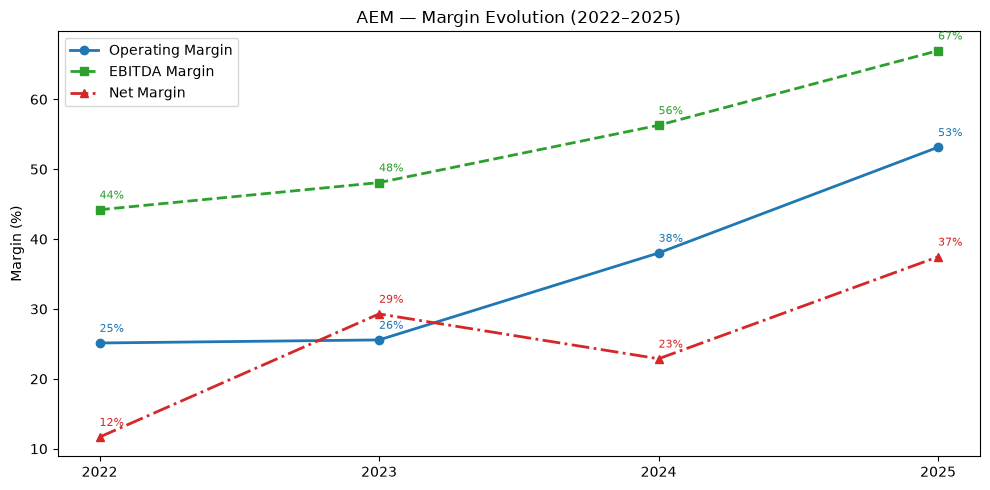

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

years = pivot_margins["fiscal_date"].str[:4].astype(int)

ax.plot(years, pivot_margins["Operating_Margin"], marker="o", linestyle="-", label="Operating Margin", color="#1f77b4", linewidth=2)
ax.plot(years, pivot_margins["EBITDA_Margin"], marker="s", linestyle="--", label="EBITDA Margin", color="#2ca02c", linewidth=2)
ax.plot(years, pivot_margins["Net_Margin"], marker="^", linestyle="-.", label="Net Margin", color="#d62728", linewidth=2)

# Label each point with its value
for series, color in [("Operating_Margin", "#1f77b4"), ("EBITDA_Margin", "#2ca02c"), ("Net_Margin", "#d62728")]:
    for x, y in zip(years, pivot_margins[series]):
        ax.annotate(f"{y:.0f}%", (x, y), textcoords="offset points", xytext=(0, 8), fontsize=8, color=color)

ax.set_title("AEM — Margin Evolution (2022–2025)")
ax.set_ylabel("Margin (%)")
ax.set_xticks(years)
ax.legend()
plt.tight_layout()
plt.show()

- Operating margin rose from 25% to 53% and the cost ratio fell from 65% to 42% between 2022
and 2025. EBITDA margin, calculated as operating income plus depreciation, rose from 44% to
67%. The EBITDA reported by yfinance was not used: it moves differently (59% in 2023, 53% in
2024, while operating margin kept rising), which suggests it includes non-operating items.

- Two cautions. First, 2022 absorbs one-time merger costs: the cost ratio likely includes a
$158.5M non-cash inventory revaluation from merger accounting (about 2.8 points; excluding it,
roughly 62.3%). Second, these changes coincide with higher gold prices, so they cannot be
attributed to the merger on their own (see the peer comparison below). Net margin also
includes non-operating items: in 2023, net income exceeded operating income.

- Depreciation ($1.09B in 2022) matches the cash flow statement but is below the company's
mid-2022 guidance ($1.25–1.35B), which was issued before the purchase price allocation was
finalized in Q4 2022. If actual depreciation was closer to that guidance, the 2022 EBITDA
margin would be about 3–4 points higher; the trend through 2025 would not change.

## Peer Margin Comparison

To see how much of the margin expansion is shared across the sector, the same margins are
computed for Newmont (NEM) and Barrick (B), gold producers exposed to the same gold prices.
Neither is a clean control: Newmont completed its own large acquisition (Newcrest, November
2023), which may distort its 2023 figures, and both may carry company-specific effects.

In [9]:
peer_margins = {}
for ticker in ["NEM", "B"]:
    fin = yf.Ticker(ticker).financials
    rev = fin.loc["Total Revenue"]
    df = pd.DataFrame({
        f"{ticker}_Operating_Margin": fin.loc["Operating Income"] / rev * 100,
        f"{ticker}_Cost_Ratio": fin.loc["Cost Of Revenue"] / rev * 100,
    })
    df.index = df.index.year
    peer_margins[ticker] = df

aem_margins = pivot_margins[["Operating_Margin", "Cost_Ratio"]].copy()
aem_margins.index = pivot_margins["fiscal_date"].str[:4].astype(int)
aem_margins.columns = ["AEM_Operating_Margin", "AEM_Cost_Ratio"]

comparison = (
    aem_margins
    .join(peer_margins["NEM"], how="inner")
    .join(peer_margins["B"], how="inner")
    .sort_index()
    .round(1)
)
comparison

,AEM_Operating_Margin,AEM_Cost_Ratio,NEM_Operating_Margin,NEM_Cost_Ratio,B_Operating_Margin,B_Cost_Ratio
fiscal_date,,,,,,
2022,25.1,65.1,13.5,72.6,27.5,68.1
2023,25.6,66.8,6.0,74.6,24.7,69.6
2024,38.0,55.5,31.6,61.8,32.4,61.6
2025,53.1,41.9,48.6,46.8,47.2,48.7


AEM, Newmont and Barrick show a similar pattern between 2022 and 2025. Operating margin rose by
28 points at AEM (25% to 53%), 35 at Newmont (13% to 49%) and 20 at Barrick (27% to 47%); the
cost ratio fell by 23, 26 and 19 points respectively. AEM ends 2025 with the highest operating
margin and the lowest cost ratio of the three, but its improvement sits between its peers':
larger than Barrick's, smaller than Newmont's. Its cost-ratio advantage did not widen
consistently either: versus Barrick it grew from 3.0 to 6.8 points, versus Newmont it narrowed
from 7.5 to 4.9.

## Gold Price Check

To test the gold-price explanation directly, the table and chart below index the average gold
price (COMEX futures), AEM's revenue and AEM's cost of revenue to 2022 = 100.

,Gold_Price,AEM_Revenue,AEM_Cost_Of_Revenue
2022,100.0,100.0,100.0
2023,108.0,115.0,118.0
2024,133.0,144.0,123.0
2025,192.0,207.0,133.0


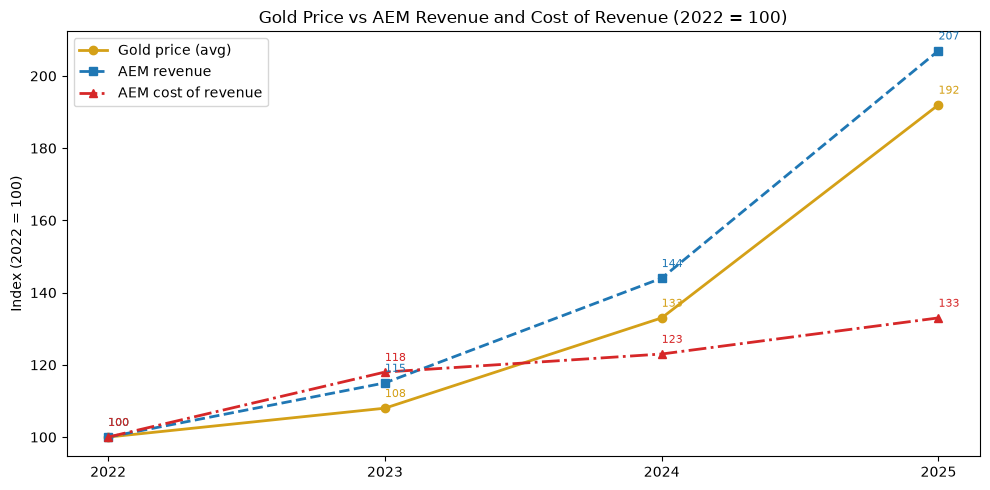

In [10]:
gold = yf.Ticker("GC=F").history(start="2022-01-01", end="2026-01-01")
gold_yearly = gold["Close"].groupby(gold.index.year).mean()

aem_fin = pivot_margins.copy()
aem_fin.index = pivot_margins["fiscal_date"].str[:4].astype(int)

gold_check = pd.DataFrame({
    "Gold_Price": gold_yearly,
    "AEM_Revenue": aem_fin["Total Revenue"],
    "AEM_Cost_Of_Revenue": aem_fin["Cost Of Revenue"],
}).dropna()

# index each column to 2022 = 100
gold_index = (gold_check / gold_check.iloc[0] * 100).round(0)
display(gold_index)

fig, ax = plt.subplots(figsize=(10, 5))
styles = [
    ("Gold_Price", "Gold price (avg)", "o", "-", "#d4a017"),
    ("AEM_Revenue", "AEM revenue", "s", "--", "#1f77b4"),
    ("AEM_Cost_Of_Revenue", "AEM cost of revenue", "^", "-.", "#d62728"),
]
for col, label, marker, linestyle, color in styles:
    ax.plot(gold_index.index, gold_index[col], marker=marker, linestyle=linestyle,
            label=label, color=color, linewidth=2)
    for x, y in zip(gold_index.index, gold_index[col]):
        ax.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(0, 8), fontsize=8, color=color)

ax.set_title("Gold Price vs AEM Revenue and Cost of Revenue (2022 = 100)")
ax.set_ylabel("Index (2022 = 100)")
ax.set_xticks(gold_index.index)
ax.legend()
plt.tight_layout()
plt.show()

Between 2022 and 2025 the average gold price rose about 92%, AEM's revenue about 107% and its
cost of revenue about 33% (about 39% excluding the one-time 2022 inventory adjustment). Revenue
grew somewhat faster than the gold price, consistent with some added volume (company guidance,
not actual production, implied about 7% production growth from 2022 to 2025), while costs grew
far less, so margins widened. The data does not show how much of the slow cost growth comes from
merger synergies (reported at roughly $30–40 per ounce, about 4–5% of unit cash costs) and how
much from the fact that mining costs largely do not rise with the gold price. The gold series is
a futures proxy; AEM's realized price may differ.

## Valuation Multiple Check

If AEM's margins did not improve more than its peers', the stock's larger gain may reflect a
higher multiple paid by the market. The table below shows year-end price, diluted EPS and
P/E (year-end price / diluted EPS) for AEM, Newmont and Barrick. P/E is left blank when EPS is
negative.

In [11]:
pe_tables = []

for t in ["AEM", "NEM", "B"]:
    tk = yf.Ticker(t)

    # unadjusted prices: adjusting for dividends would distort the P/E
    px = tk.history(start="2022-01-01", end="2026-01-01", auto_adjust=False)["Close"]
    year_end_price = px.groupby(px.index.year).last()

    eps = tk.financials.loc["Diluted EPS"]
    eps.index = eps.index.year

    df = pd.DataFrame({"Price": year_end_price, "EPS": eps}).dropna()
    df["PE"] = (df["Price"] / df["EPS"]).where(df["EPS"] > 0)
    df.columns = [f"{t}_{c}" for c in df.columns]
    pe_tables.append(df)

pe_table = pd.concat(pe_tables, axis=1).sort_index().round(2)
pe_table

,AEM_Price,AEM_EPS,AEM_PE,NEM_Price,NEM_EPS,NEM_PE,B_Price,B_EPS,B_PE
2022,51.99,1.53,33.98,47.20,-0.54,NaN,17.18,0.24,71.58
2023,54.85,3.95,13.89,41.39,-2.94,NaN,18.09,0.72,25.13
2024,78.21,3.78,20.69,37.22,2.92,12.75,15.50,1.22,12.70
2025,169.53,8.86,19.13,99.85,6.39,15.63,43.55,2.93,14.86


Only 2024 and 2025 are comparable across the three companies: in 2022–2023 the P/E is
distorted (AEM's 2022 EPS absorbs merger costs, Newmont's EPS is negative, and Barrick's 2022
EPS is very low). In 2024–2025 AEM traded at 19–21 times earnings against 13–16 for Newmont and
Barrick, a premium of roughly 60% in 2024 and 20–30% in 2025. AEM's EPS grew from $1.53 to $8.86
between 2022 and 2025, from a base depressed by merger costs; peers' EPS also recovered from very
low or negative levels, so growth rates are not directly comparable. The higher multiple is
consistent with the market paying a premium for AEM, which would help explain the larger stock
gain. The data cannot show whether that premium is due to the merger or to other factors such as
asset quality and jurisdiction.

## Unit Cost Check

AISC (all-in sustaining cost) per ounce isolates cost from the gold price, unlike margins. The
table below uses the figures each company reported in its full-year results (SEC filings and
company releases). Definitions differ across companies, so the comparison is of each company's
change over 2022–2025, not of levels. Notes: AEM's 2022 figure includes the Kirkland Lake mines
only from February 8 (pro forma full year: $1,090); Newmont's series is on its co-product basis
(its by-product AISC was $1,408 in 2024 and $1,358 in 2025) and its 2023 jump coincides with the
Newcrest acquisition and a strike at Peñasquito; Barrick's 2025 production fell 17%.

In [12]:
# All-in sustaining cost (AISC) per ounce of gold, as reported by each company (USD/oz).
# Sources: full-year results releases (SEC 6-K / annual report / company websites).
aisc = pd.DataFrame(
    {
        "AEM": [1109, 1179, 1239, 1339],
        "NEM": [1211, 1444, 1516, 1609],
        "B":   [1222, 1335, 1484, 1637],
    },
    index=[2022, 2023, 2024, 2025],
)
display(aisc)

change = pd.DataFrame({
    "USD_per_oz": aisc.loc[2025] - aisc.loc[2022],
    "Pct_change": ((aisc.loc[2025] / aisc.loc[2022] - 1) * 100).round(1),
})
change

,AEM,NEM,B
2022,1109,1211,1222
2023,1179,1444,1335
2024,1239,1516,1484
2025,1339,1609,1637


,USD_per_oz,Pct_change
AEM,230,20.7
NEM,398,32.9
B,415,34.0


## Conclusion

**Verdict**: Agnico Eagle reported early synergy progress and kept unit-cost growth below its
peers', but the reported synergy amounts explain only a small part of that difference and of the
margin expansion, which follows the gold price. The data collected here cannot show whether the
merger explains the stock's outperformance.

- **Deal terms**: all-stock, 0.7935 AEM shares per KL share, implied C$50.63 per KL share,
  a 9% discount to the September 27, 2021 close.

- **Reported synergies** (company 6-K filings): target of $800M over 5 years and $2B over 10,
  pre-tax. Corporate G&A synergies exceeded the original estimate (~$40M realized by mid-2022;
  estimate raised to up to $225M over 5 years). Operational synergies ramp up through 2029 and
  are estimated at up to $30–40 per ounce, roughly 4–5% of unit cash costs.

- **Margins**: AEM's operating margin rose from 25% to 53% (2022–2025) and its cost ratio fell
  from 65% to 42%. Newmont and Barrick, exposed to the same gold prices, improved by similar
  amounts (operating margin +35 and +20 points, against +28 at AEM). Over the same period the
  average gold price rose about 92% and AEM's revenue about 107%, while its cost of revenue rose
  about 33%, so the expansion follows from revenue growing much faster than costs. AEM's
  cost-ratio advantage over peers did not widen consistently. Neither peer is a clean control
  (Newmont completed Newcrest in 2023). The 2022 cost ratio also includes a $158.5M non-cash
  inventory adjustment from merger accounting.

- **Unit costs**: AISC per ounce rose about 21% at AEM ($1,109 to $1,339) between 2022 and 2025,
  against about 33% at Newmont and 34% at Barrick, while the gold price roughly doubled. AEM's
  cost growth was about $170–185 per ounce lower than its peers'. The reported merger synergies
  ($30–40 per ounce at full run-rate) would explain roughly a fifth of that gap at most; the rest
  cannot be attributed with this data (the peers had volume declines, the integration of
  Newcrest and different cost definitions).

- **Stock performance and valuation**: AEM returned +320% since the announcement date, against
  +147% for Newmont and +162% for Barrick (dividend-adjusted). In 2024–2025 AEM traded at 19–21
  times earnings against 13–16 for the peers (earlier years are distorted), a premium consistent
  with the larger gain. The data cannot separate the merger from asset quality (e.g., Detour
  Lake), jurisdiction or other factors.

- **Limitations**: yfinance provides only 2022–2025, so there are no pre-merger margins; the
  gold series is a futures proxy, not AEM's realized price; P/E uses reported diluted EPS, which
  includes one-time items; AISC definitions differ across companies; cumulative synergies
  realized through 2025 were not verified; and there is no counterfactual for what AEM would
  have achieved without the merger.